### Mounting G. Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Installing pyAudioAnalysis

In [2]:
!git clone https://github.com/tyiannak/pyAudioAnalysis.git
!pip install -r /content/pyAudioAnalysis/requirements.txt
!pip install -e /content/pyAudioAnalysis/

Cloning into 'pyAudioAnalysis'...
remote: Enumerating objects: 3057, done.
remote: Counting objects: 100% (530/530), done.
remote: Compressing objects: 100% (132/132), done.
remote: Total 3057 (delta 437), reused 403 (delta 398), pack-reused 2527 (from 1)
Receiving objects: 100% (3057/3057), 167.67 MiB | 29.35 MiB/s, done.
Resolving deltas: 100% (1825/1825), done.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.0/166.0 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.4/140.4 kB 16.8 MB/s eta 0:00:00
Obtaining file:///content/pyAudioAnalysis
  Preparing metadata (setup.py) ... done
  Running setup.py develop for pyAudioAnalysis


### Reading ASVSpoof dataset from kaggle




In [ ]:
%pip install -q -U kagglehub soundfile

In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
ulianazb_asvspoof_2024_path = kagglehub.dataset_download('ulianazb/asvspoof-2024')

print('Data source import complete.')


In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
#kagglehub.dataset_download('ulianazb/asvspoof-2024')


In [ ]:
import kagglehub
import pandas as pd

DATASET = "ulianazb/asvspoof-2024"

# Use o caminho exato mostrado na lista acima
METADADOS = "ASVspoof5.train.metadata.txt"

# Baixa somente o arquivo de metadados
arquivo = kagglehub.dataset_download(DATASET, path=METADADOS)

df = pd.read_csv(
    arquivo,
    sep=r"\s+",
    header=None,
    dtype=str,
    keep_default_na=False
)

df.columns = [
        "speaker_id", "file_id", "gender",
        "extra", "attack", "label"
    ]

classes = ["bonafide", "spoof"]
dados = df[df["label"].isin(classes)].copy()

contagens = dados["label"].value_counts().reindex(classes, fill_value=0)
n = int(min(1000, contagens.min()))


df_amostra = (
    dados.groupby("label")
    .sample(n=n, random_state=42)
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

df_amostra.to_csv("/content/df_amostra.csv", index=False)
print("\nCSV salvo em /content/df_amostra.csv")

print("Recordings by label:")
print(df["label"].value_counts())

print("\nRecordings by attack:")
print(df["attack"].value_counts())

print("\nSampled Recordings by label:")
print(df_amostra["label"].value_counts())

print("\nSampled Recordings by attack:")
print(df_amostra["attack"].value_counts())



display(df_amostra.head())

100%|██████████| 1.06M/1.06M [00:00<00:00, 11.1MB/s]

Extracting zip of ASVspoof5.train.metadata.txt...



CSV salvo em /content/df_amostra.csv
Recordings by label:
label
spoof       163560
bonafide     18797
Name: count, dtype: int64

Recordings by attack:
attack
A05         20445
A07         20445
A04         20445
A08         20445
A02         20445
A03         20445
A06         20445
A01         20445
bonafide    18797
Name: count, dtype: int64

Sampled Recordings by label:
label
spoof       1000
bonafide    1000
Name: count, dtype: int64

Sampled Recordings by attack:
attack
bonafide    1000
A01          134
A07          131
A08          131
A05          127
A02          122
A06          121
A04          117
A03          117
Name: count, dtype: int64


,speaker_id,file_id,gender,extra,attack,label
0,T_4277,T_0000037890,F,-,A07,spoof
1,T_0696,T_0000161723,F,-,bonafide,bonafide
2,T_0012,T_0000061246,M,-,A06,spoof
3,T_4243,T_0000146026,M,-,bonafide,bonafide
4,T_2176,T_0000156350,F,-,A06,spoof


In [ ]:
# Testing download of one sample
from pathlib import Path
import soundfile as sf
from IPython.display import Audio, display

row = df.iloc[1]
file_id = row["file_id"]
filename = file_id if file_id.endswith(".flac") else f"{file_id}.flac"

audio_path = kagglehub.dataset_download(
    "ulianazb/asvspoof-2024",
    path=f"flac_T/flac_T/{filename}",
    output_dir="/content/asvspoof_amostra")

print("Audio filenamer:", audio_path, flush=True)
waveform, sample_rate = sf.read(audio_path)
display(Audio(waveform, rate=sample_rate))


100%|██████████| 120k/120k [00:00<00:00, 1.80MB/s]

Audio filenamer: /content/asvspoof_amostra/flac_T/flac_T/T_0000000001.flac


In [ ]:
import subprocess
from tqdm.auto import tqdm

ARQUIVO_CSV = "/content/df_amostra.csv"
DATASET = "ulianazb/asvspoof-2024"
DESTINO = Path("/content/asvspoof_amostra")
DESTINO.mkdir(parents=True, exist_ok=True)

df_amostra = pd.read_csv(ARQUIVO_CSV, dtype=str)

caminhos_locais = []

for file_id in tqdm(df_amostra["file_id"], desc="Baixando áudios"):
    file_id = file_id.strip()
    nome = file_id if file_id.endswith(".flac") else f"{file_id}.flac"

    arquivo = f"flac_T/flac_T/{nome}"
    caminho_local = DESTINO / nome

    if not caminho_local.is_file():
        subprocess.run(
            [
                "kaggle", "datasets", "download",
                DATASET,
                "-f", arquivo,
                "-p", str(DESTINO),
                "--unzip",
                "-q"
            ],
            check=True
        )

    if not caminho_local.is_file():
        raise FileNotFoundError(f"Arquivo não encontrado: {caminho_local}")

    caminhos_locais.append(str(caminho_local))

# Mantém os rótulos e registra os caminhos locais
df_amostra["audio_path"] = caminhos_locais
df_amostra.to_csv(DESTINO / "metadados.csv", index=False)

print(f"\nConcluído: {len(caminhos_locais)} áudios disponíveis.")
display(df_amostra.head())

In [ ]:
import numpy as np
from scipy.io import wavfile
import plotly.graph_objs as go
from plotly.subplots import make_subplots

pasta = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"

fs_b, bona = wavfile.read(f"{pasta}/treino/bonafide/T_0000013293.wav")
fs_s, spoof = wavfile.read(f"{pasta}/treino/spoof/T_0000050020.wav")

fig = make_subplots(rows=1, cols=2, subplot_titles=["bonafide", "Spoof"])
fig.add_trace(go.Scatter(x=np.arange(len(bona)) / fs_b, y=bona, name="bonafide"), row=1, col=1)
fig.add_trace(go.Scatter(x=np.arange(len(spoof)) / fs_s, y=spoof, name="Spoof", line=dict(color="red")), row=1, col=2)
fig.show()

In [ ]:
import numpy as np
from scipy.io import wavfile
import plotly.graph_objs as go
from plotly.subplots import make_subplots

pasta = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"

fs_b, bona = wavfile.read(f"{pasta}/treino/bonafide/T_0000013293.wav")
fs_s, spoof = wavfile.read(f"{pasta}/treino/spoof/T_0000050020.wav")

# Função para normalizar de acordo com o dtype do áudio
def normalizar_audio(sinal):
    if sinal.dtype == np.int16:
        return sinal / 32768.0
    elif sinal.dtype == np.int32:
        return sinal / 2147483648.0
    elif sinal.dtype == np.float32 or sinal.dtype == np.float64:
        return sinal # Já está em float
    return sinal / np.max(np.abs(sinal)) # Fallback para o máximo absoluto

bona_norm = normalizar_audio(bona)
spoof_norm = normalizar_audio(spoof)

fig = make_subplots(rows=1, cols=2, subplot_titles=["Bonafide (Normalizado)", "Spoof (Normalizado)"])

fig.add_trace(go.Scatter(x=np.arange(len(bona_norm)) / fs_b, y=bona_norm, name="bonafide"), row=1, col=1)
fig.add_trace(go.Scatter(x=np.arange(len(spoof_norm)) / fs_s, y=spoof_norm, name="Spoof", line=dict(color="red")), row=1, col=2)

fig.update_layout(yaxis=dict(range=[-1, 1]), yaxis2=dict(range=[-1, 1]))
fig.show()

### Features extraction

In [ ]:
%cd /content/pyAudioAnalysis/pyAudioAnalysis
!python3 audioAnalysis.py featureExtractionDir -i "/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino"  -mw 1.0 -ms 1.0 -sw 0.050 -ss 0.050
!python3 audioAnalysis.py featureExtractionDir -i "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste"  -mw 1.0 -ms 1.0 -sw 0.050 -ss 0.050
!pip install "numpy<2"

In [ ]:
# Extrai as features de cada pasta (treino/teste x bonafide/spoof) com janela de 0.5s (passo de 0.25s)

%cd /content/pyAudioAnalysis/pyAudioAnalysis
caminho = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"

for conjunto in ["treino", "teste"]:
    for classe in ["bonafide", "spoof"]:
        pasta = f"{caminho}/{conjunto}/{classe}"
        print("Extraindo features de:", pasta)
        !python3 audioAnalysis.py featureExtractionDir -i "{pasta}" -mw 0.5 -ms 0.25 -sw 0.050 -ss 0.025




> Concatenation of the features extracted from the mid-term windows of each audio file


In [ ]:
import glob, os
import numpy as np
import pandas as pd

pasta = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"

# nomes das features (34 + deltas)
feats = ["zcr", "energy", "energy_entropy", "spectral_centroid", "spectral_spread",
         "spectral_entropy", "spectral_flux", "spectral_rolloff"]
feats += [f"mfcc_{i}" for i in range(1, 14)]
feats += [f"chroma_{i}" for i in range(1, 13)] + ["chroma_std"]
feats += ["delta_" + f for f in feats]

colunas = [f + "_mean" for f in feats] + [f + "_std" for f in feats]


def resume_audio(csv_st, tam=20, passo=10):
    # janela de 0.5s = 20 frames, passo de 0.25s = 10 frames
    frames = np.loadtxt(csv_st, delimiter=",")
    janelas = []
    for i in range(0, max(len(frames) - tam, 0) + 1, passo):
        bloco = frames[i:i + tam]
        janelas.append(np.concatenate([bloco.mean(axis=0), bloco.std(axis=0)]))
    return np.mean(janelas, axis=0)


dados = []
for conjunto in ["treino", "teste"]:
    for classe in ["bonafide", "spoof"]:
        for csv_st in glob.glob(f"{pasta}/{conjunto}/{classe}/*_st.csv"):
            linha = list(resume_audio(csv_st)) + [os.path.basename(csv_st), classe, conjunto]
            dados.append(linha)

df = pd.DataFrame(dados, columns=colunas + ["arquivo", "classe", "conjunto"])
df.to_csv(f"{pasta}/features_por_audio.csv", index=False)
print(df.shape)

### Exploratory data analysis (EDA)

> Feature–class correlation (per-audio)



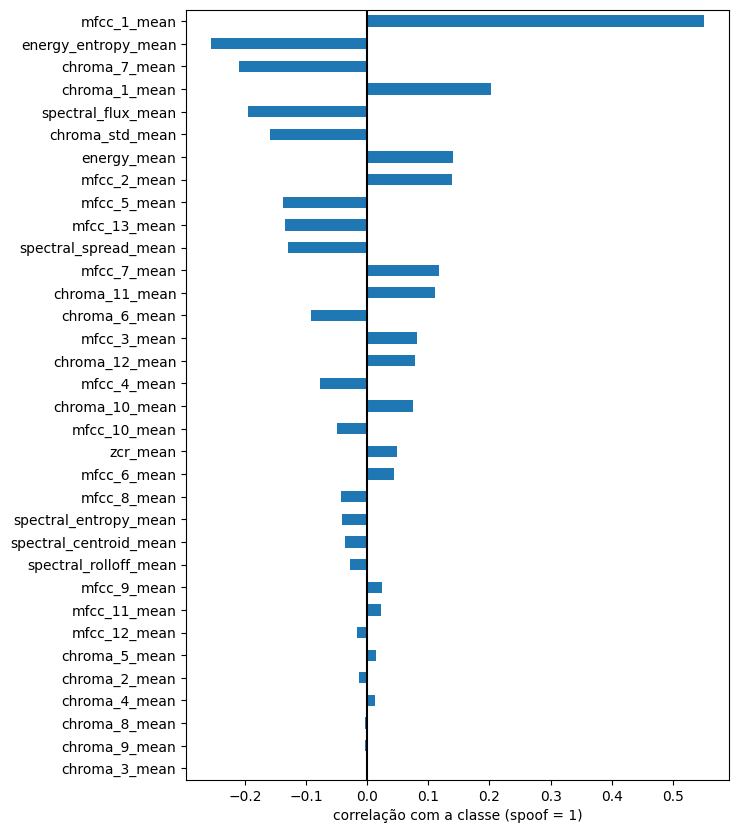

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt


df = pd.read_csv(f"{pasta}/features_por_audio.csv")
df_treino = df[df["conjunto"] == "treino"]

features = df_treino.columns[:34]
y = (df_treino["classe"] == "spoof").astype(int)

corr = df_treino[features].corrwith(y)
corr = corr.sort_values(key=abs, ascending=False)

corr.plot.barh(figsize=(7, 10))
plt.axvline(0, color="k")
plt.xlabel("correlação com a classe (spoof = 1)")
plt.gca().invert_yaxis()
plt.show()



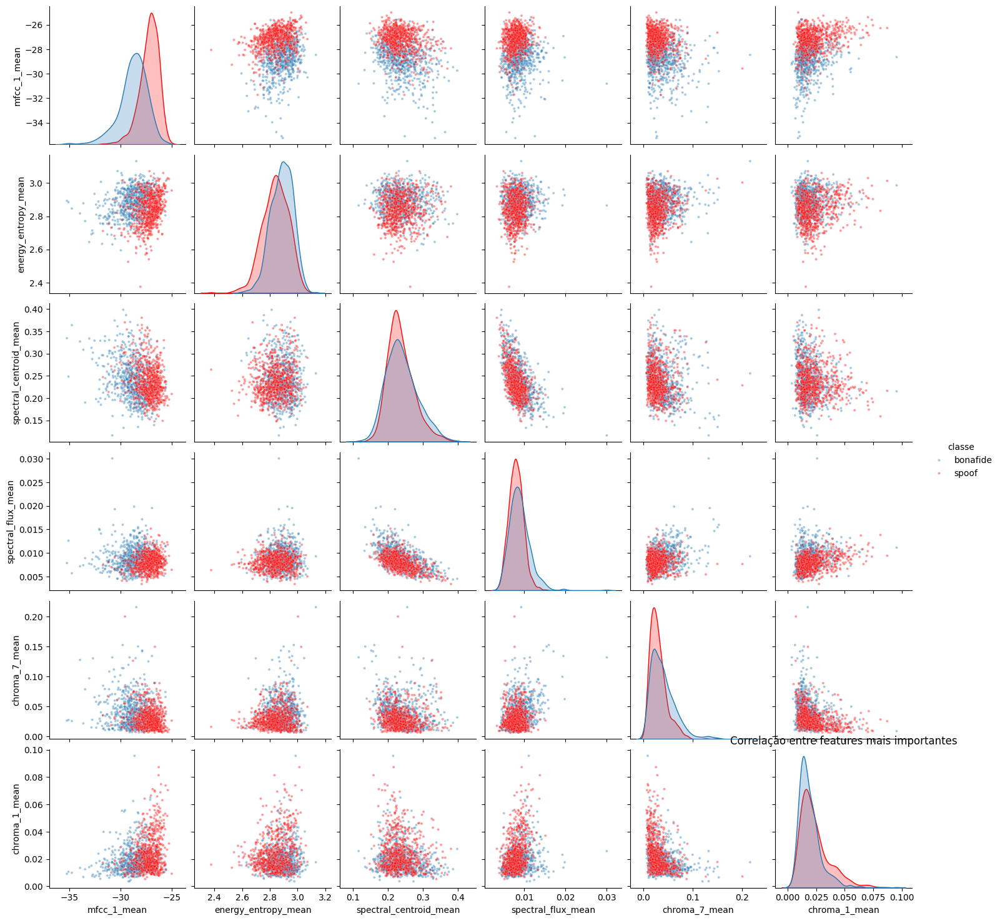

In [ ]:
import seaborn as sns

feats = ["mfcc_1_mean", "energy_entropy_mean", "spectral_centroid_mean",
         "spectral_flux_mean","chroma_7_mean" , "chroma_1_mean"]

sns.pairplot(df_treino[feats + ["classe"]], hue="classe",
             palette={"bonafide": "tab:blue", "spoof": "red"},
             plot_kws={"s": 8, "alpha": 0.4})
plt.title("Correlação entre features mais importantes")
plt.show()



> Correlation among the 10-top features



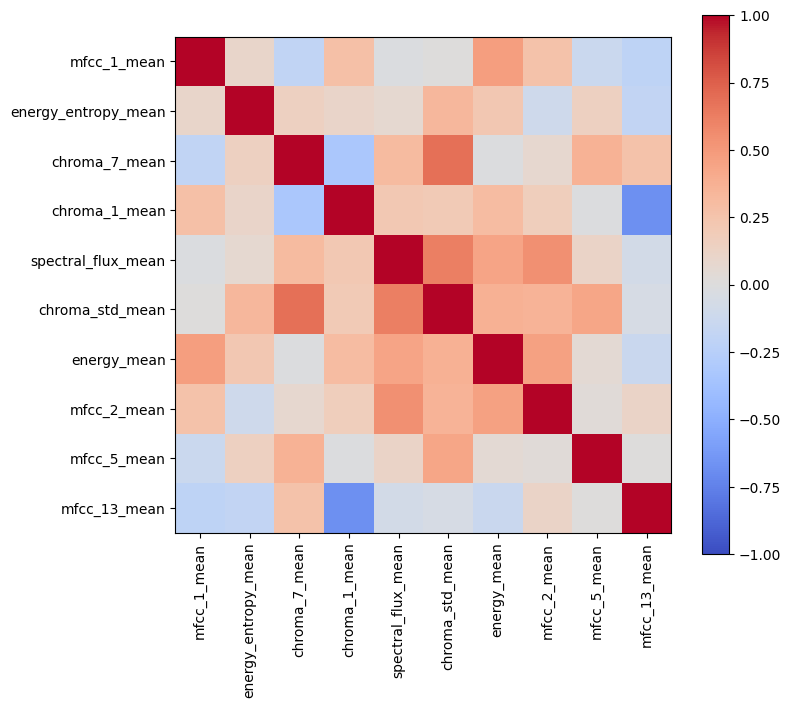

In [ ]:
top = corr.head(10).index
plt.figure(figsize=(8, 7))
plt.imshow(df_treino[top].corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(top)), top, rotation=90)
plt.yticks(range(len(top)), top)
plt.show()



> Characteristics of audio signal



          count        mean         std    min    25%    50%    75%    max
classe                                                                    
bonafide  700.0  593.697143  114.101853  400.0  494.0  591.0  687.0  799.0
spoof     700.0  464.660000  114.956302  210.0  382.0  452.0  539.0  918.0


<Axes: title={'center': 'frames'}, xlabel='classe'>

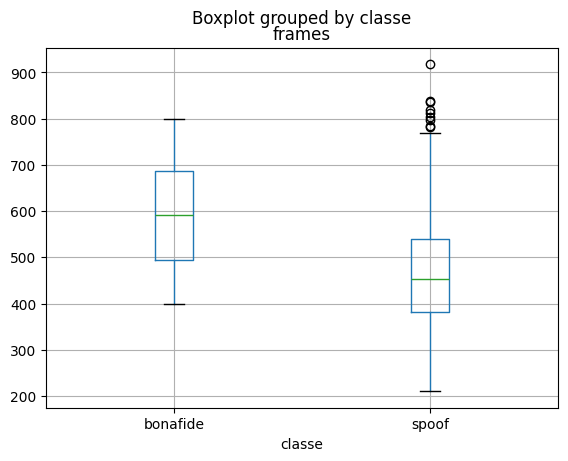

In [ ]:
pastas_treino = [
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide",
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/spoof",
]

arquivos_treino, y_treino = [], []
for pasta in pastas_treino:
    classe = "bonafide" if "bonafide" in pasta else "spoof"
    for f in sorted(glob.glob(os.path.join(pasta, "*_st.csv"))):
        arquivos_treino.append(f)
        y_treino.append(classe)


comprimentos = [len(np.loadtxt(f, delimiter=",")) for f in arquivos_treino]
tab = pd.DataFrame({"frames": comprimentos, "classe": y_treino})
print(tab.groupby("classe")["frames"].describe())
tab.boxplot(by="classe", column="frames")

          count      mean       std       min       25%       50%       75%  \
classe                                                                        
bonafide  700.0  0.287291  0.055053  0.043578  0.253827  0.286877  0.324516   
spoof     700.0  0.232440  0.053209  0.000000  0.195461  0.228717  0.267566   

               max  
classe              
bonafide  0.465969  
spoof     0.382775  


<Axes: title={'center': 'silencio'}, xlabel='classe'>

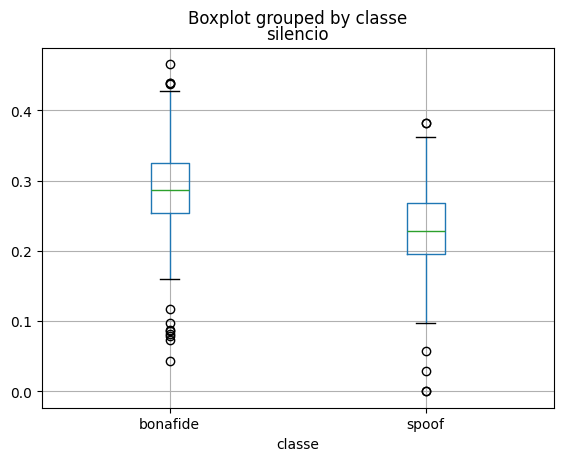

In [ ]:
def prop_silencio(csv_st):
    e = np.loadtxt(csv_st, delimiter=",")[:, 1]   # coluna 1 = energy
    limiar = 0.1 * np.median(e)                    # silencio = < 10% da energia tipica
    return (e < limiar).mean()                     # fracao de frames silenciosos

sil = [prop_silencio(f) for f in arquivos_treino]
tab = pd.DataFrame({"silencio": sil, "classe": y_treino})
print(tab.groupby("classe")["silencio"].describe())
tab.boxplot(by="classe", column="silencio")



> PCA 2D projection


*   áudios do locutor T_0012
*   Comparação de 4 áudios bonafide e 3 ataques (A05, A06, A08)

In [ ]:
import shutil, os, glob

destino = "/content/pca_T0012"
os.makedirs(destino, exist_ok=True)

audios = {
    "T_0000013293": "bonafide",
    "T_0000154639": "bonafide",
    "T_0000129935": "bonafide",
    "T_0000063828": "bonafide",
    "T_0000050020": "A05",
    "T_0000061246": "A06",
    "T_0000053944": "A08",
}

# copia os áudios
shutil.rmtree(destino, ignore_errors=True)
os.makedirs(destino, exist_ok=True)

for fid, grupo in audios.items():
    arq = glob.glob(f"{pasta}/*/*/{fid}.wav")[0]
    rotulo = f"{grupo}_{fid[-4:]}"            # ex.: bonafide_3293, A05_0020
    shutil.copy(arq, f"{destino}/{rotulo} --- {fid}.wav")

print(os.listdir(destino))

['A05_0020 --- T_0000050020.wav', 'bonafide_4639 --- T_0000154639.wav', 'A08_3944 --- T_0000053944.wav', 'bonafide_9935 --- T_0000129935.wav', 'bonafide_3293 --- T_0000013293.wav', 'A06_1246 --- T_0000061246.wav', 'bonafide_3828 --- T_0000063828.wav']


/content/pyAudioAnalysis/pyAudioAnalysis
Analyzing file 1 of 7: /content/pca_T0012/A05_0020 --- T_0000050020.wav
Analyzing file 2 of 7: /content/pca_T0012/A06_1246 --- T_0000061246.wav
Analyzing file 3 of 7: /content/pca_T0012/A08_3944 --- T_0000053944.wav
Analyzing file 4 of 7: /content/pca_T0012/bonafide_3293 --- T_0000013293.wav
Analyzing file 5 of 7: /content/pca_T0012/bonafide_3828 --- T_0000063828.wav
Analyzing file 6 of 7: /content/pca_T0012/bonafide_4639 --- T_0000154639.wav
Analyzing file 7 of 7: /content/pca_T0012/bonafide_9935 --- T_0000129935.wav
Feature extraction complexity ratio: 27.9 x realtime


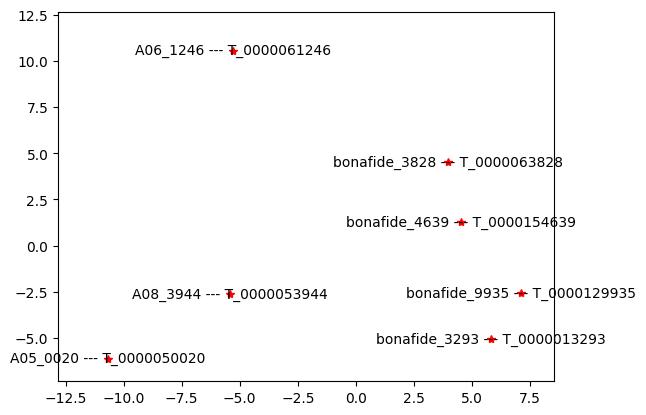

In [ ]:
%cd /content/pyAudioAnalysis/pyAudioAnalysis
import numpy

if not hasattr(numpy, "Inf"):
    numpy.Inf = numpy.inf
if not hasattr(numpy, "NaN"):
    numpy.NaN = numpy.nan

from pyAudioAnalysis import audioVisualization as aV

aV.visualizeFeaturesFolder(destino, "pca", "")

### Features analysis (per-frame)





> *MFCC 1 (Mel-Frequency Cepstral Coefficient 1)* - In pyAudioAnalysis, `mfcc_1` is the first of these coefficients (the 0th DCT term). It is the average of the log-energies across all mel bands, so it mainly reflects the overall loudness of the frame on a logarithmic scale. Values closer to zero indicate louder frames, and very negative values indicate quiet frames or silence.

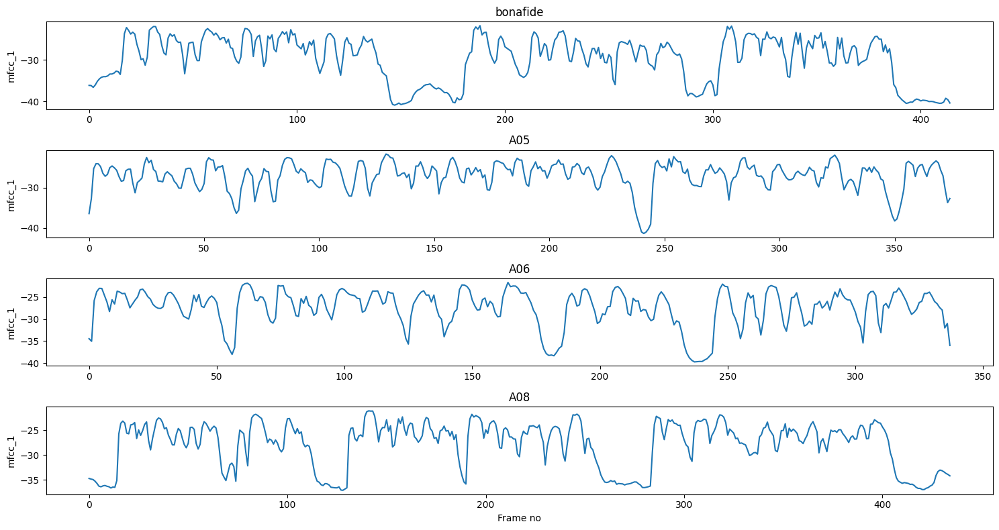

In [ ]:
from pyAudioAnalysis import audioBasicIO, ShortTermFeatures
import matplotlib.pyplot as plt
dir = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"

audios = {
    "bonafide": f"{dir}/treino/bonafide/T_0000013293.wav",
    "A05": f"{dir}/treino/spoof/T_0000050020.wav",
    "A06": f"{dir}/treino/spoof/T_0000061246.wav",
    "A08": f"{dir}/treino/spoof/T_0000053944.wav",
}

plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[8, :])
    plt.title(nome)
    plt.ylabel(f_names[8])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()

> *Zero Crossing Rate* (*ZCR*) - rate of sign changes of the signal during the duration of a frame. High values indicate noisy or high-frequency content (e.g. fricatives like "s" and "f", or background noise), low values indicate voiced, lower-frequency sounds like vowels.



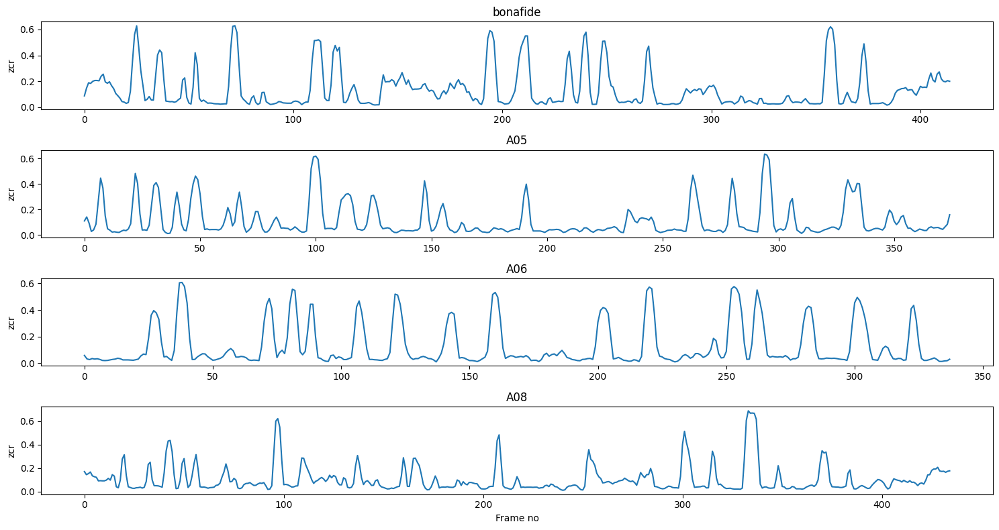

In [ ]:
plt.figure(figsize=(15, 8))
for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[0, :])
    plt.title(nome)
    plt.ylabel(f_names[0])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()


> *energy* is the sum of squares of the signal values, normalized by the respective frame length. It's a measure of signal strength.




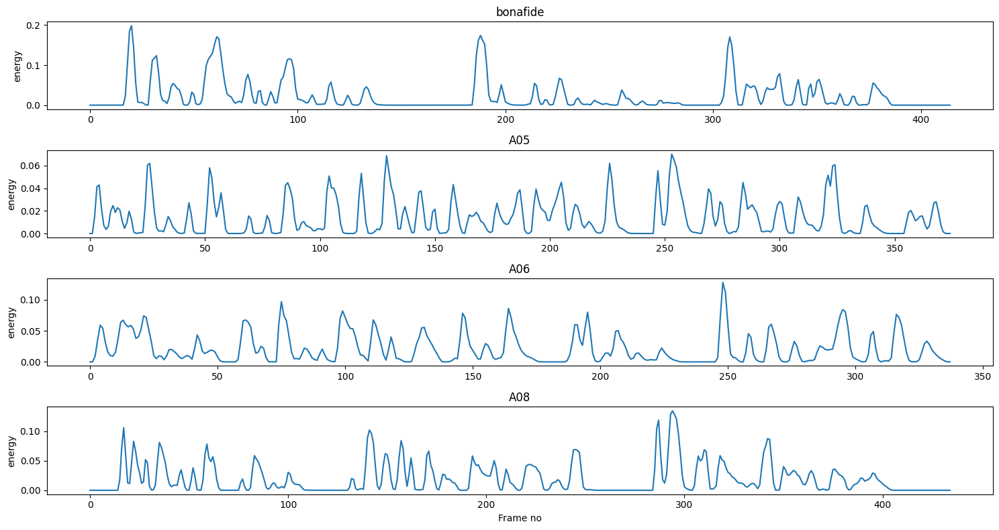

In [ ]:
plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[1, :])
    plt.title(nome)
    plt.ylabel(f_names[1])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Entropy of energy* - the entropy of sub-frames normalized energy. It can be interpreted as a measure of abrupt changes.



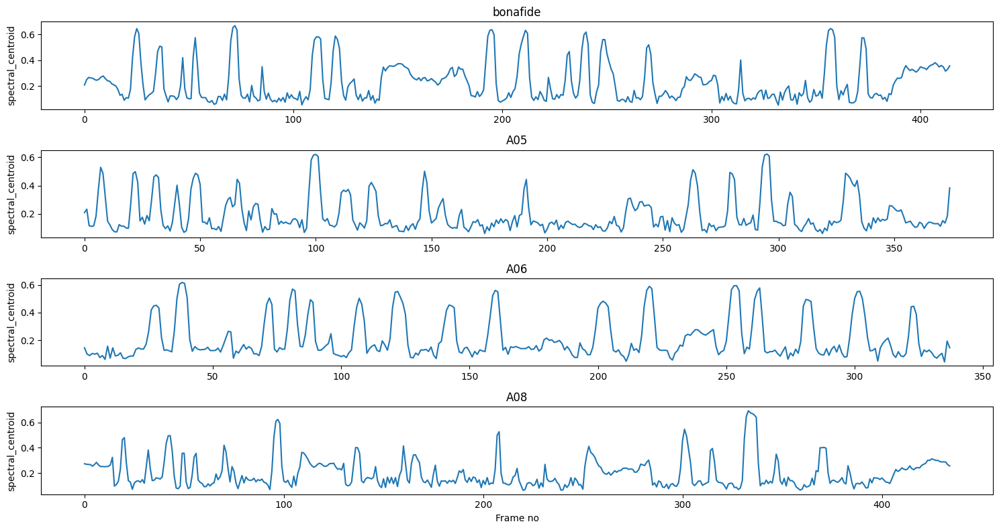

In [ ]:

plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[3, :])
    plt.title(nome)
    plt.ylabel(f_names[3])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Spectral_centroid* - the center of gravity (mean) of the spectrum. It relates to the perceived brightness of the sound: higher values mean more high-frequency content.



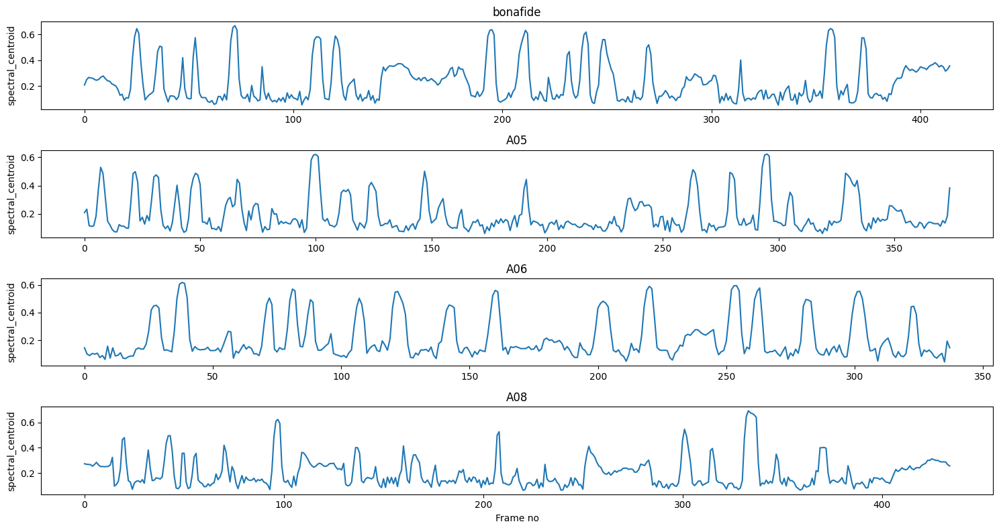

In [ ]:
plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[3, :])
    plt.title(nome)
    plt.ylabel(f_names[3])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



>





> *Spectral_spread* - the second central moment of the spectrum, i.e. how spread out the frequencies are around the centroid.



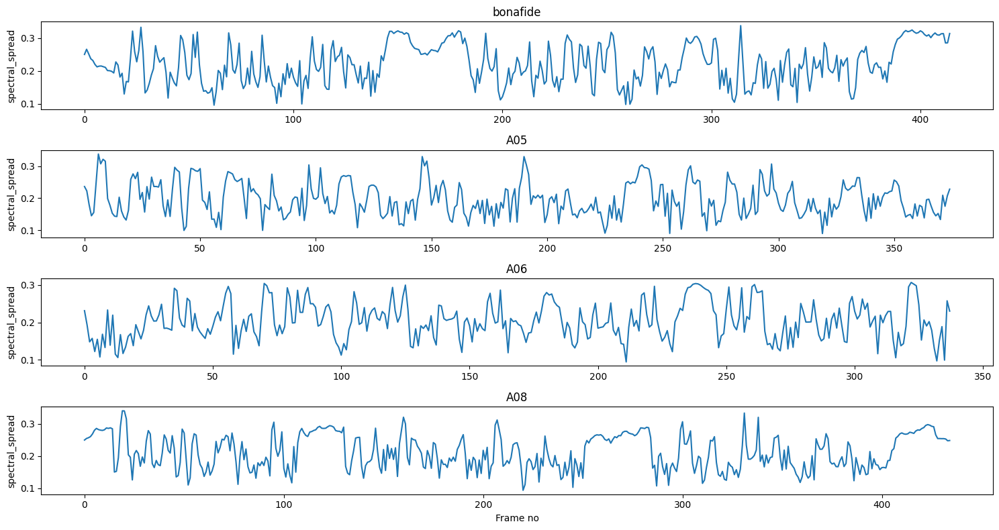

In [ ]:

plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[4, :])
    plt.title(nome)
    plt.ylabel(f_names[4])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Spectral_entropy* - the entropy of the normalized spectral energies. It measures how flat or peaky the spectrum is.



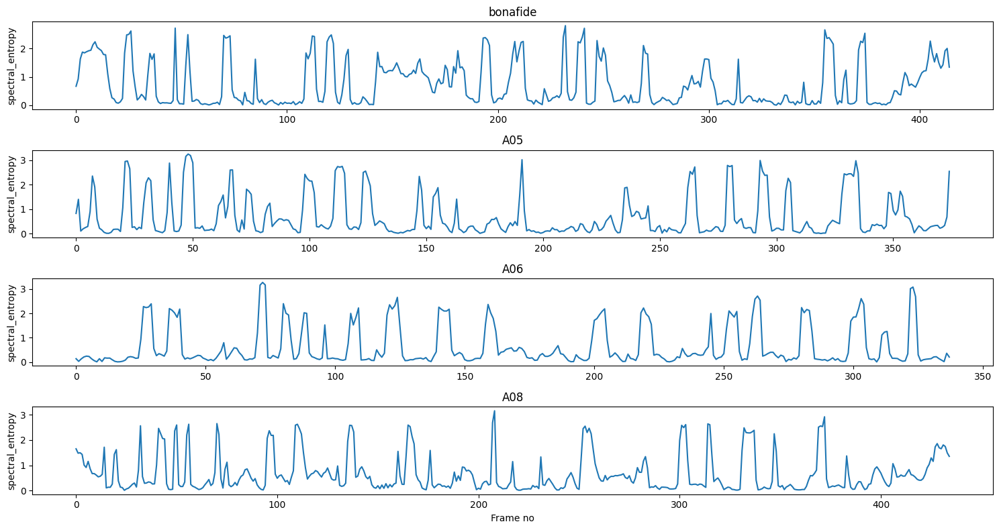

In [ ]:

plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[5, :])
    plt.title(nome)
    plt.ylabel(f_names[5])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Spectral_flux* - the squared difference between the normalized spectra of two successive frames. It measures how fast the spectrum changes over time.


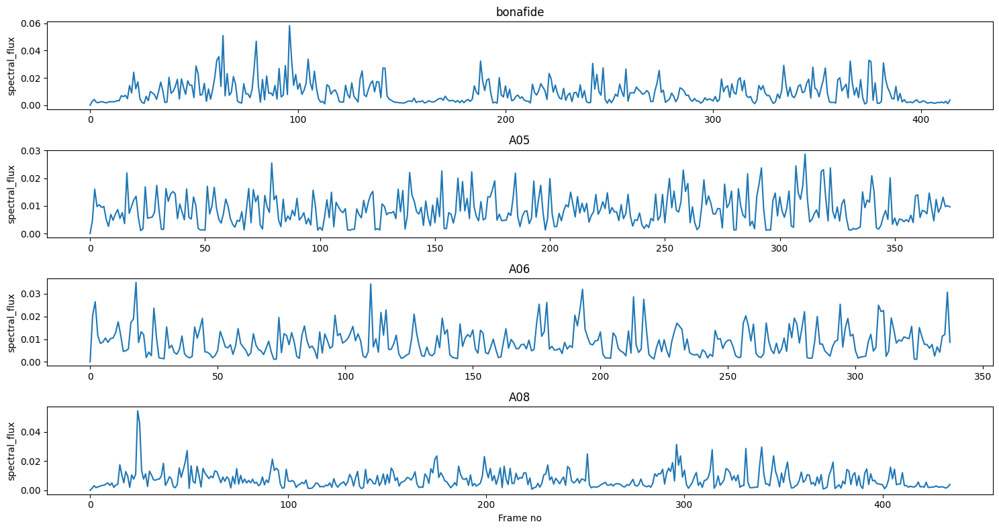

In [ ]:

plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[6, :])
    plt.title(nome)
    plt.ylabel(f_names[6])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Chroma1* - The energy of the signal distributed over the 12 pitch classes.


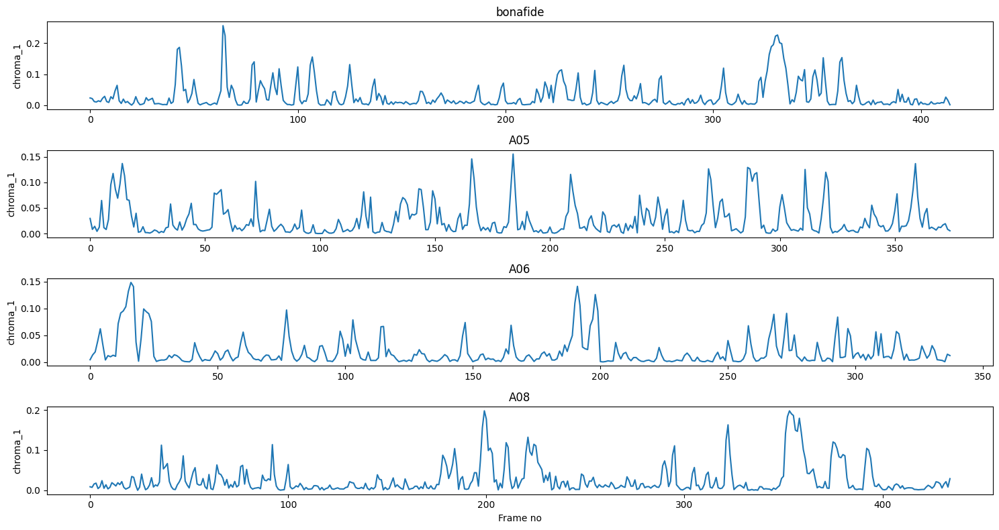

In [ ]:
plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[21, :])
    plt.title(nome)
    plt.ylabel(f_names[21])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()



> *Chroma7* - The energy of the signal distributed over the 12 pitch classes.



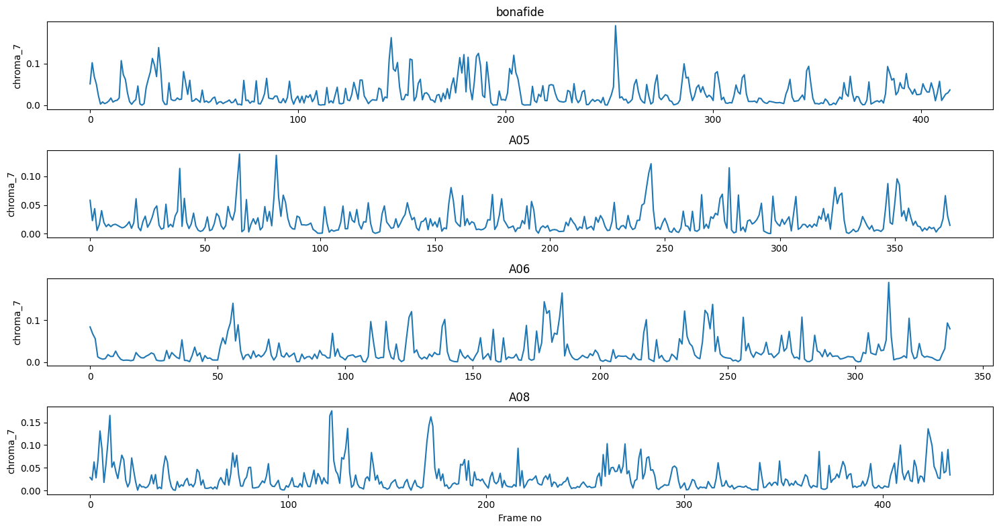

In [ ]:
plt.figure(figsize=(15, 8))

for i, (nome, arq) in enumerate(audios.items(), start=1):
    [Fs, x] = audioBasicIO.read_audio_file(arq)
    F, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

    plt.subplot(4, 1, i)
    plt.plot(F[27, :])
    plt.title(nome)
    plt.ylabel(f_names[27])

plt.xlabel("Frame no")
plt.tight_layout()
plt.show()

# Classifiers trainning

### splitting audios apart in train/test

In [ ]:
from pathlib import Path
import pandas as pd
import soundfile as sf
from sklearn.model_selection import train_test_split

# Caminhos
pasta_audios = Path("/content/drive/MyDrive/Aula 03 - dataset/asvspoof_amostra")
metadados = "/content/drive/MyDrive/Aula 03 - dataset/asvspoof_amostra/metadados.csv"
pasta_saida = Path("/content/drive/MyDrive/Aula 03 - dataset/audios_final")

# Lê arquivos
dados = pd.read_csv(metadados, sep=None, engine="python", dtype=str)
dados = dados[["file_id", "label"]].copy()
dados.columns = ["arquivo", "classe"]

dados["classe"] = dados["classe"].str.strip().str.lower()
dados["arquivo"] = dados["arquivo"].str.strip().map(
    lambda nome: Path(nome).stem + ".flac"
)

# Separa 70-30 treino e teste
treino, teste = train_test_split(
    dados,
    test_size=0.30,
    stratify=dados["classe"],
    random_state=42
)

# Converte para WAV
for conjunto, amostras in [("treino", treino), ("teste", teste)]:
    for amostra in amostras.itertuples(index=False):
        destino = pasta_saida / conjunto / amostra.classe
        destino.mkdir(parents=True, exist_ok=True)

        origem = pasta_audios / amostra.arquivo
        nome_wav = Path(amostra.arquivo).with_suffix(".wav")

        audio, taxa = sf.read(origem, dtype="int32")
        sf.write(destino / nome_wav, audio, taxa, subtype="PCM_32")

# Salve a divisão para os próximos experimentos
divisao = pd.concat([
    treino.assign(conjunto="treino"),
    teste.assign(conjunto="teste")
])

divisao.to_csv(pasta_saida / "divisao.csv", index=False)
print(pd.crosstab(divisao["conjunto"], divisao["classe"]))

### SVM Classifier trainning

In [ ]:
from pyAudioAnalysis import audioTrainTest as aT
import os

print("Iniciando o treinamento do modelo")


%cd /content/pyAudioAnalysis/pyAudioAnalysis


!python3 audioAnalysis.py trainClassifier -i \
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide" \
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/spoof" \
    --method svm -o svmSMtemp

# Validação rápida com classificação individual
test_file = "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/bonafide/T_0000000376.wav"
print(f"\nValidando treino no {test_file} ")
result = aT.file_classification(test_file, "/content/pyAudioAnalysis/pyAudioAnalysis/svmSMtemp", "svm")
print(result)

Iniciando o treinamento do modelo
/content/pyAudioAnalysis/pyAudioAnalysis
Analyzing file 1 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000000539.wav
Analyzing file 2 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000001323.wav
Analyzing file 3 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000002403.wav
Analyzing file 4 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000002537.wav
Analyzing file 5 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000002658.wav
Analyzing file 6 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000003038.wav
Analyzing file 7 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000003172.wav
Analyzing file 8 of 700: /content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000004057.wav
Analyzing file 9 of 700: /con

### Saving the Trained Model

In [ ]:
import os
import shutil

pasta_origem = "/content/pyAudioAnalysis/pyAudioAnalysis"
save_dir = "/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos"
os.makedirs(save_dir, exist_ok=True)

for arquivo in ["svmSMtemp", "svmSMtempMEANS"]:
    shutil.copy(os.path.join(pasta_origem, arquivo), os.path.join(save_dir, arquivo))

print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


> Test split evaluation



              precision    recall  f1-score   support

    bonafide     0.9211    0.9333    0.9272       300
       spoof     0.9324    0.9200    0.9262       300

    accuracy                         0.9267       600
   macro avg     0.9267    0.9267    0.9267       600
weighted avg     0.9267    0.9267    0.9267       600



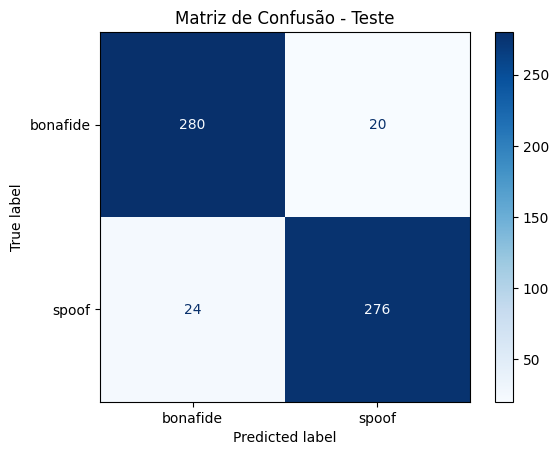

In [ ]:
import os, numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from pyAudioAnalysis import audioTrainTest as aT

pastas_teste = [
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/bonafide",
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/spoof",
]
modelo   = "/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos/svmSMtemp"
save_dir = "/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos"
os.makedirs(save_dir, exist_ok=True)
rotulos = ["bonafide", "spoof"]

# prediz cada audio
y_real, y_pred = [], []
for pasta in pastas_teste:
    classe = "bonafide" if "bonafide" in pasta else "spoof"
    for wav in sorted(glob.glob(os.path.join(pasta, "*.wav"))):
        c, prob, nomes = aT.file_classification(wav, modelo, "svm")
        y_real.append(classe)
        y_pred.append(nomes[int(c)])

# metricas prontas
print(classification_report(y_real, y_pred, labels=rotulos, digits=4))

# matriz de confusao
cm = confusion_matrix(y_real, y_pred, labels=rotulos)
ConfusionMatrixDisplay(cm, display_labels=rotulos).plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - Teste"); plt.show()

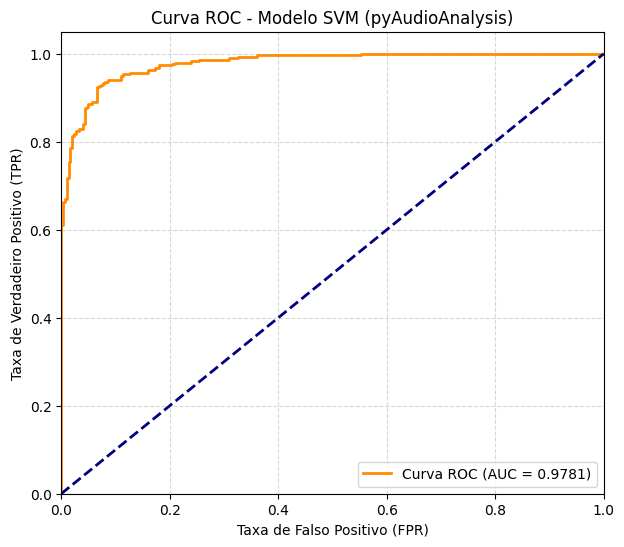

In [ ]:
import glob, os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from pyAudioAnalysis import audioTrainTest as aT

pastas_teste = [
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/bonafide",
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/spoof",
]
modelo = "/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos/svmSMtemp"

y_real_bin = []
y_probs_svm = []

# Obter as probabilidades para cada arquivo de áudio no conjunto de teste
for pasta in pastas_teste:
    classe_true = 1 if "spoof" in pasta else 0
    for wav in sorted(glob.glob(os.path.join(pasta, "*.wav"))):
        c, prob, nomes = aT.file_classification(wav, modelo, "svm")

        # Descobrir qual índice em 'nomes' corresponde à classe 'spoof'
        idx_spoof = nomes.index("spoof")

        y_real_bin.append(classe_true)
        y_probs_svm.append(prob[idx_spoof])

# Calcular métricas da curva ROC
fpr, tpr, _ = roc_curve(y_real_bin, y_probs_svm)
roc_auc = auc(fpr, tpr)

# Plotar a curva ROC
plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Curva ROC (AUC = {roc_auc:.4f})")
plt.plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taxa de Falso Positivo (FPR)")
plt.ylabel("Taxa de Verdadeiro Positivo (TPR)")
plt.title("Curva ROC - Modelo SVM (pyAudioAnalysis)")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()



> Feature importance

In [ ]:
from pyAudioAnalysis import audioTrainTest as aT
import pandas as pd
import matplotlib.pyplot as plt

# modelo treinado
svm, _, _, classes, _, _, _, _, _ = aT.load_model("/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos/svmSMtemp")


df = pd.read_csv("/content/drive/MyDrive/Aula 03 - dataset/audios_final/features_por_audio.csv")
nomes = df.columns[:136]

# peso de cada feature
pesos = pd.Series(svm.coef_[0], index=nomes)


top20 = pesos[pesos.abs().sort_values(ascending=False).index[:20]]

top20.plot.barh(figsize=(7, 7))
plt.axvline(0, color="k")
plt.xlabel(f"peso no SVM (positivo = {classes[1]})")
plt.gca().invert_yaxis()
plt.show()

### GBooting classifier trainning

In [9]:
import pandas as pd
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, f1_score
from sklearn.ensemble import HistGradientBoostingClassifier

df = pd.read_csv("/content/drive/MyDrive/Aula 03 - dataset/audios_final/features_por_audio.csv")
colunas = list(df.columns[:136]) + ["classe"]

treino = df[df["conjunto"] == "treino"][colunas]
teste = df[df["conjunto"] == "teste"][colunas]

features = list(df.columns[:136])

modelo = HistGradientBoostingClassifier(random_state=42)

parametros = {
    "learning_rate": [0.05, 0.1],
    "max_depth": [None, 5, 10],
    "max_iter": [100, 300],
}

busca = GridSearchCV(modelo, parametros, cv=5, scoring='f1_macro', n_jobs=-1)
busca.fit(treino[features], treino["classe"])

print("Melhores parâmetros:", busca.best_params_)
print("F1 (validação cruzada):", busca.best_score_)

gb = busca.best_estimator_
pred = gb.predict(teste[features])
print("F1 no teste:", f1_score(teste["classe"], pred, pos_label="spoof"))

Melhores parâmetros: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 300}
F1 (validação cruzada): 0.9435563917094024
F1 no teste: 0.9429530201342282


=== Relatório de Classificação ===
              precision    recall  f1-score   support

    bonafide       0.94      0.95      0.94       300
       spoof       0.95      0.94      0.94       300

    accuracy                           0.94       600
   macro avg       0.94      0.94      0.94       600
weighted avg       0.94      0.94      0.94       600



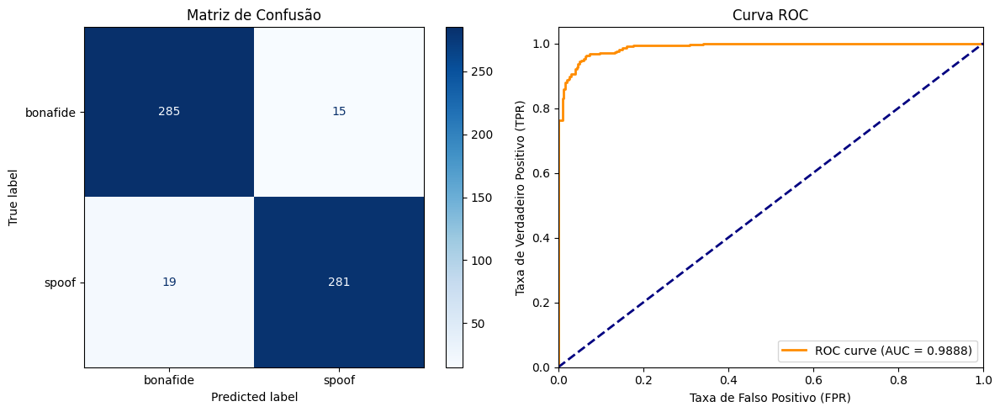

In [10]:
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc

# Treinar o modelo final com os melhores parâmetros
modelo_final = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=5,
    max_iter=300,
    random_state=42
)
modelo_final.fit(treino[features], treino["classe"])

# Predições e probabilidades
y_pred = modelo_final.predict(teste[features])
y_probs = modelo_final.predict_proba(teste[features])[:, 1]  # Probabilidade da classe positiva ('spoof')

# Converter classe para binário (0 e 1) para a curva ROC (spoof = 1)
y_test_bin = (teste["classe"] == "spoof").astype(int)

# Métricas
print("=== Relatório de Classificação ===")
print(classification_report(teste["classe"], y_pred))

# Matriz de Confusão e Curva ROC em subplots
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(teste["classe"], y_pred, cmap="Blues", ax=ax[0])
ax[0].set_title("Matriz de Confusão")

fpr, tpr, _ = roc_curve(y_test_bin, y_probs)
roc_auc = auc(fpr, tpr)

ax[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC curve (AUC = {roc_auc:.4f})")
ax[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
ax[1].set_xlim([0.0, 1.0])
ax[1].set_ylim([0.0, 1.05])
ax[1].set_xlabel("Taxa de Falso Positivo (FPR)")
ax[1].set_ylabel("Taxa de Verdadeiro Positivo (TPR)")
ax[1].set_title("Curva ROC")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()



> Features evaluation using permutation importance


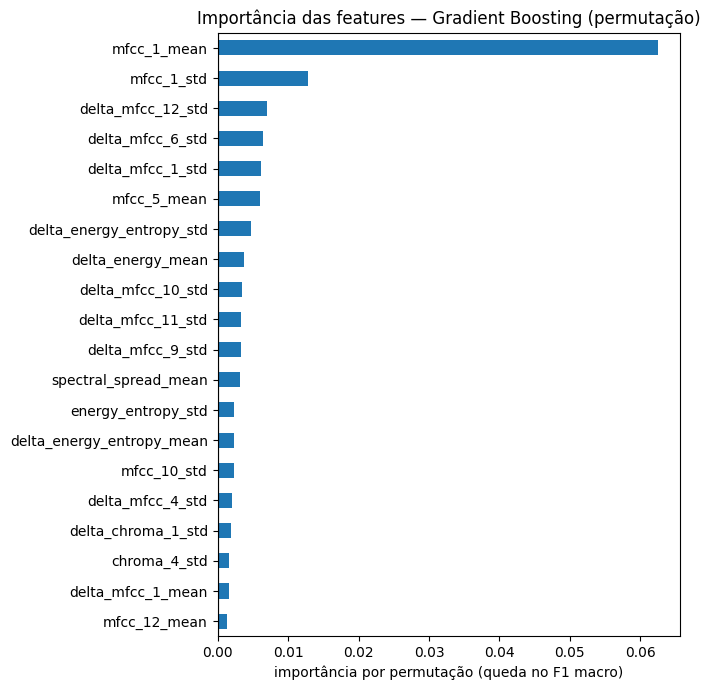

Top 5 (permutação): ['mfcc_1_mean', 'mfcc_1_std', 'delta_mfcc_12_std', 'delta_mfcc_6_std', 'delta_mfcc_1_std']


In [13]:
from sklearn.inspection import permutation_importance
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

Xtreino = df[df["conjunto"] == "treino"][colunas]
ytreino = df[df["conjunto"] == "treino"]["classe"]

Xteste = df[df["conjunto"] == "teste"][colunas]
Xteste = Xteste.drop(columns="classe")
yteste = df[df["conjunto"] == "teste"]["classe"]

# Calculando permutation importance
imp = permutation_importance(modelo_final, Xteste, yteste, n_repeats=10, random_state=42, scoring="f1_macro")


rank = pd.Series(imp.importances_mean, index=Xteste.columns).sort_values(ascending=False)




rank.head(20).plot.barh(figsize=(7, 7))
plt.axvline(0, color="k")
plt.xlabel("importância por permutação (queda no F1 macro)")
plt.title("Importância das features — Gradient Boosting (permutação)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()



F1 (top 10 features): 0.898
              precision    recall  f1-score   support

    bonafide       0.92      0.87      0.89       300
       spoof       0.88      0.92      0.90       300

    accuracy                           0.90       600
   macro avg       0.90      0.90      0.89       600
weighted avg       0.90      0.90      0.89       600



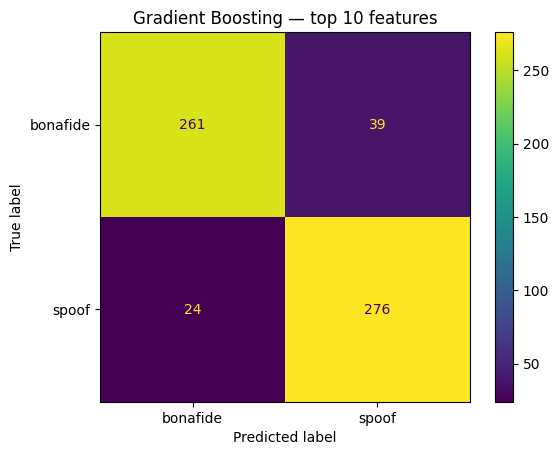

In [ ]:
# Retreinando GBoosting com as top-10 features

top10 = list(rank.head(10).index)

reduzido = HistGradientBoostingClassifier(random_state=42).fit(Xtreino[top10], ytreino)
pred = reduzido.predict(Xteste[top10])
f1_red = f1_score(yteste, pred, pos_label="spoof")
print(f"F1 (top {len(top10)} features):", round(f1_red, 3))

print(classification_report(yteste, pred))
ConfusionMatrixDisplay.from_predictions(yteste, pred, labels=["bonafide","spoof"])
plt.title(f"Gradient Boosting — top {len(top10)} features")
plt.show()

### RNN GRU

In [3]:
import pandas as pd

# ===== Hiperparâmetros =====
N_FEATURES = 68        # 34 features + 34 deltas
MAX_FRAMES = None
VAL_SPLIT = 0.2        # conjunto para validação
SEED = 42

TIPO_RNN = "GRU"
HIDDEN_SIZE = 32
NUM_CAMADAS = 1
DROPOUT = 0.3

BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCAS = 40
PACIENCIA = 5

pasta = "/content/drive/MyDrive/Aula 03 - dataset/audios_final"
df = pd.read_csv("/content/drive/MyDrive/Aula 03 - dataset/audios_final/features_por_audio.csv")
features_cols = list(df.columns[:136])

df_treino = df[df["conjunto"] == "treino"]
df_teste = df[df["conjunto"] == "teste"]

X_train = df_treino[features_cols].values
y_train = (df_treino["classe"] == "spoof").astype(int).values

X_test = df_teste[features_cols].values
y_test = (df_teste["classe"] == "spoof").astype(int).values


In [4]:
import numpy as np
import torch
import torch.nn as nn
import glob
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence
from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

class ModeloGRU(nn.Module):
    def __init__(self):
        super().__init__()
        self.gru = nn.GRU(
            input_size=N_FEATURES,
            hidden_size=HIDDEN_SIZE,
            num_layers=NUM_CAMADAS,
            batch_first=True,
        )
        self.dropout = nn.Dropout(DROPOUT)
        self.saida = nn.Linear(HIDDEN_SIZE, 1)

    def forward(self, x, tamanhos):
        x = nn.utils.rnn.pack_padded_sequence(
            x, tamanhos.cpu(), batch_first=True, enforce_sorted=False)
        _, h = self.gru(x)
        return self.saida(self.dropout(h[-1])).squeeze(1)


def carrega(conjunto):
    X, y = [], []
    for classe in ["bonafide", "spoof"]:
        for arq in sorted(glob.glob(f"{pasta}/{conjunto}/{classe}/*_st.csv")):
            x = np.loadtxt(arq, delimiter=",")       # (n_frames, 68)
            if MAX_FRAMES:
                x = x[:MAX_FRAMES]                   # corta em MAX_FRAMES
            X.append(x)
            y.append(1.0 if classe == "spoof" else 0.0)
    return X, np.array(y, dtype=np.float32)

X_treino, y_treino = carrega("treino")
X_teste, y_teste = carrega("teste")


# Split para validação estratificada
X_tr, X_val, y_tr, y_val = train_test_split(
    X_treino, y_treino, test_size=VAL_SPLIT, stratify=y_treino, random_state=SEED)


# normaliza
todos = np.vstack(X_tr)
media = todos.mean(axis=0)
desvio = todos.std(axis=0) + 1e-8

def normaliza(X):
    return [torch.tensor((x - media) / desvio, dtype=torch.float32) for x in X]

X_tr, X_val, X_te = normaliza(X_tr), normaliza(X_val), normaliza(X_teste)


# monta os lotes e faz padding
def junta_lote(lote):
    xs, ys = zip(*lote)
    tamanhos = torch.tensor([len(x) for x in xs])
    x = pad_sequence(xs, batch_first=True)
    return x, tamanhos, torch.tensor(ys)

treino_loader = DataLoader(list(zip(X_tr, y_tr)), batch_size=BATCH_SIZE, shuffle=True, collate_fn=junta_lote)
val_loader = DataLoader(list(zip(X_val, y_val)), batch_size=BATCH_SIZE, shuffle=False, collate_fn=junta_lote)
teste_loader = DataLoader(list(zip(X_te, y_teste)), batch_size=BATCH_SIZE, shuffle=False, collate_fn=junta_lote)

In [5]:
##################################
########### Treinamento ##########
##################################
device = "cuda" if torch.cuda.is_available() else "cpu"

torch.manual_seed(SEED)
np.random.seed(SEED)
modelo_RNN = ModeloGRU().to(device)
perda = torch.nn.BCEWithLogitsLoss()
otimizador = torch.optim.Adam(modelo_RNN.parameters(), lr=LEARNING_RATE)

def roda_epoca(loader, treinar):
    modelo_RNN.train(treinar)
    soma_loss, acertos, total = 0, 0, 0

    for x, tamanhos, y in tqdm(loader, leave=False,           # barra dos lotes
                               desc="treino" if treinar else "validação"):
        x, y = x.to(device), y.to(device)

        with torch.set_grad_enabled(treinar):
            saida = modelo_RNN(x, tamanhos)
            loss = perda(saida, y)

            if treinar:
                otimizador.zero_grad()
                loss.backward()
                otimizador.step()

        soma_loss += loss.item() * len(y)
        acertos += ((saida > 0) == (y == 1)).sum().item()
        total += len(y)

    return soma_loss / total, acertos / total


historico = {"loss_tr": [], "loss_val": [], "acc_tr": [], "acc_val": []}
melhor_loss, sem_melhora = float("inf"), 0

barra = tqdm(range(EPOCAS), desc="épocas")
for epoca in barra:
    loss_tr, acc_tr = roda_epoca(treino_loader, treinar=True)
    loss_val, acc_val = roda_epoca(val_loader, treinar=False)

    for chave, valor in zip(historico, [loss_tr, loss_val, acc_tr, acc_val]):
        historico[chave].append(valor)

    barra.set_postfix(loss_tr=f"{loss_tr:.4f}", loss_val=f"{loss_val:.4f}",   # mostra na barra
                      acc_val=f"{acc_val:.3f}")

    # early stopping
    if loss_val < melhor_loss:
        melhor_loss, sem_melhora = loss_val, 0
        torch.save(modelo_RNN.state_dict(), "/content/melhor_gru.pt")
    else:
        sem_melhora += 1
        if sem_melhora == PACIENCIA:
            barra.write(f"parada antecipada na época {epoca+1}")
            break


modelo_RNN.load_state_dict(torch.load("/content/melhor_gru.pt", map_location=device))
modelo_gru_treinado = modelo_RNN

épocas:   0%|          | 0/40 [00:00<?, ?it/s]

treino:   0%|          | 0/35 [00:00<?, ?it/s]

validação:   0%|          | 0/9 [00:00<?, ?it/s]

treino:   0%|          | 0/35 [00:00<?, ?it/s]

validação:   0%|          | 0/9 [00:00<?, ?it/s]

...

treino:   0%|          | 0/35 [00:00<?, ?it/s]

validação:   0%|          | 0/9 [00:00<?, ?it/s]

treino:   0%|          | 0/35 [00:00<?, ?it/s]

validação:   0%|          | 0/9 [00:00<?, ?it/s]

parada antecipada na época 19


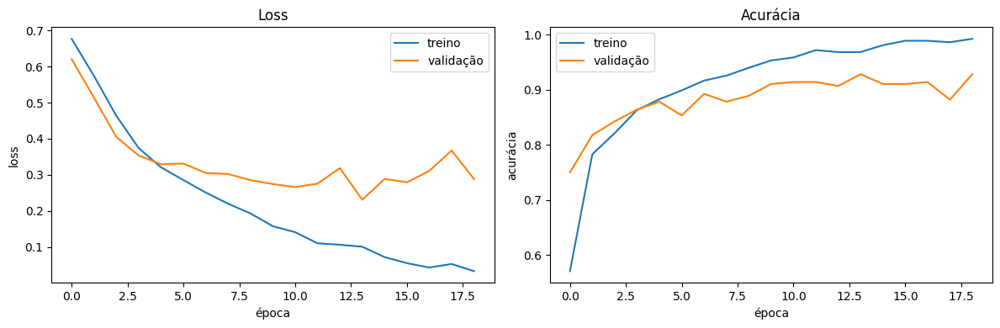

In [7]:
import  matplotlib.pyplot as plt


fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(historico["loss_tr"], label="treino")
ax[0].plot(historico["loss_val"], label="validação")
ax[0].set_xlabel("época")
ax[0].set_ylabel("loss")
ax[0].set_title("Loss")
ax[0].legend()

ax[1].plot(historico["acc_tr"], label="treino")
ax[1].plot(historico["acc_val"], label="validação")
ax[1].set_xlabel("época")
ax[1].set_ylabel("acurácia")
ax[1].set_title("Acurácia")
ax[1].legend()

plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

    bonafide      0.879     0.897     0.888       300
       spoof      0.895     0.877     0.886       300

    accuracy                          0.887       600
   macro avg      0.887     0.887     0.887       600
weighted avg      0.887     0.887     0.887       600



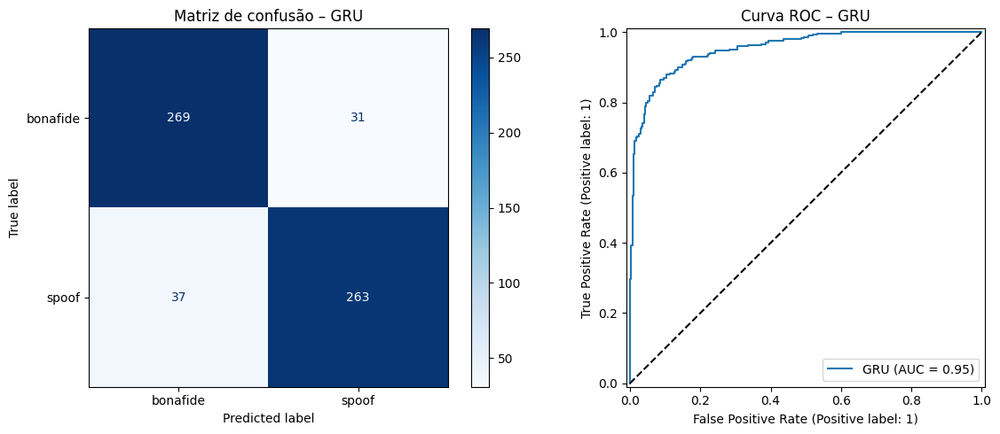

In [ ]:
##################################
### Avaliação no split de test ###
##################################

import numpy as np
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve

modelo.eval()
probs, reais = [], []
with torch.no_grad():
    for x, tamanhos, y in teste_loader:
        saida = modelo(x.to(device), tamanhos)
        probs.append(torch.sigmoid(saida).cpu().numpy())
        reais.append(y.numpy())

prob = np.concatenate(probs)
y_real = np.concatenate(reais)
pred = (prob > 0.5).astype(int)

print(classification_report(y_real, pred, target_names=["bonafide", "spoof"], digits=3))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_real, pred, display_labels=["bonafide", "spoof"],
                                        cmap="Blues", ax=ax[0])
ax[0].set_title("Matriz de confusão – GRU")
RocCurveDisplay.from_predictions(y_real, prob, name="GRU", ax=ax[1])
ax[1].plot([0, 1], [0, 1], "k--")
ax[1].set_title("Curva ROC – GRU")
plt.tight_layout()
plt.show()

fpr, tpr, _ = roc_curve(y_real, prob)


F1 com todas as features: 0.886


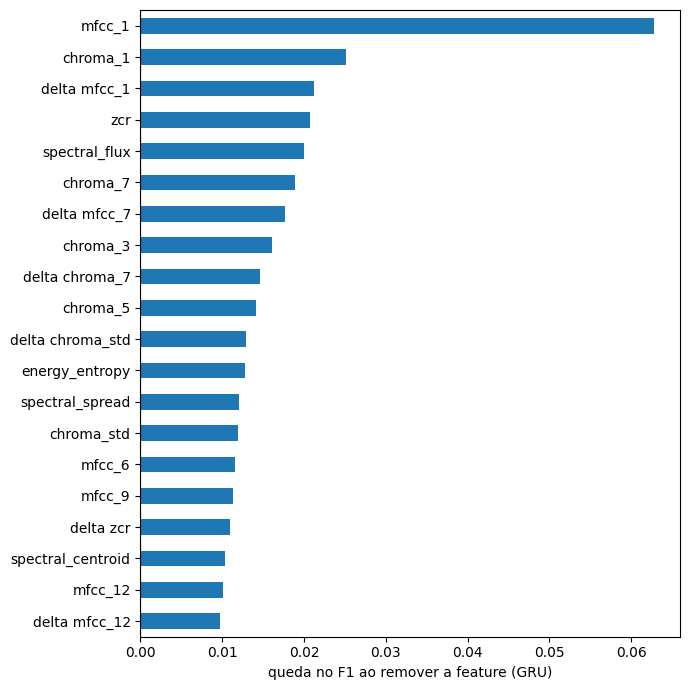

In [ ]:
import numpy as np, torch, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score
from pyAudioAnalysis import ShortTermFeatures, audioBasicIO

Fs, x = audioBasicIO.read_audio_file("/content/drive/MyDrive/Aula 03 - dataset/audios_final/treino/bonafide/T_0000000539.wav")
_, f_names = ShortTermFeatures.feature_extraction(x, Fs, 0.050*Fs, 0.025*Fs)

def avalia(zera=None):
    modelo.eval()
    probs, reais = [], []
    with torch.no_grad():
        for x, tamanhos, y in teste_loader:
            x = x.clone()
            if zera is not None:
                x[:, :, zera] = 0.0          # remove a feature (dados normalizados, media ~0)
            p = torch.sigmoid(modelo(x.to(device), tamanhos)).cpu().numpy()
            probs.append(p); reais.append(y.numpy())
    return f1_score(np.concatenate(reais), np.concatenate(probs) > 0.5)

f1_base = avalia()
print("F1 com todas as features:", round(f1_base, 3))

quedas = [f1_base - avalia(j) for j in range(len(f_names))]
imp_gru = pd.Series(quedas, index=f_names).sort_values(ascending=False)

imp_gru.head(20).plot.barh(figsize=(7, 7))
plt.axvline(0, color="k")
plt.xlabel("queda no F1 ao remover a feature (GRU)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

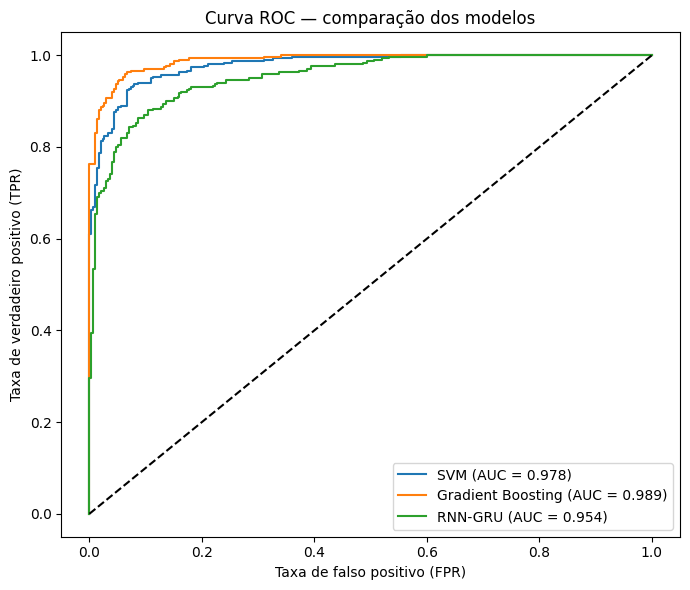

Modelos: ['SVM', 'Gradient Boosting', 'RNN-GRU']


In [12]:
import glob, os, numpy as np, matplotlib.pyplot as plt, torch
from sklearn.metrics import roc_curve, auc
from pyAudioAnalysis import audioTrainTest as aT

MODELO_GB  = modelo_final
MODELO_GRU = modelo_RNN

pastas_teste = [
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/bonafide",
    "/content/drive/MyDrive/Aula 03 - dataset/audios_final/teste/spoof",
]
modelo_svm = "/content/drive/MyDrive/Aula 03 - dataset/modelos_salvos/svmSMtemp"

curvas = []   # (nome, y, score)

# --- SVM ---
try:
    y, s = [], []
    for pasta in pastas_teste:
        classe = 1 if "spoof" in pasta else 0
        for wav in sorted(glob.glob(os.path.join(pasta, "*.wav"))):
            c, prob, nomes = aT.file_classification(wav, modelo_svm, "svm")
            y.append(classe); s.append(prob[nomes.index("spoof")])
    curvas.append(("SVM", np.array(y), np.array(s)))
except Exception as e:
    print("SVM falhou:", repr(e))

# --- Gradient Boosting ---
try:
    cols = MODELO_GB.feature_names_in_
    y = (teste["classe"] == "spoof").astype(int).values
    s = MODELO_GB.predict_proba(teste[cols])[:, 1]
    curvas.append(("Gradient Boosting", y, s))
except Exception as e:
    print("GBoosting falhou:", repr(e))

# --- GRU ---
try:
    MODELO_GRU.eval()
    probs, reais = [], []
    with torch.no_grad():
        for x, tamanhos, yb in teste_loader:
            probs.append(torch.sigmoid(MODELO_GRU(x.to(device), tamanhos)).cpu().numpy())
            reais.append(yb.numpy())
    curvas.append(("RNN-GRU", np.concatenate(reais), np.concatenate(probs)))
except Exception as e:
    print("GRU falhou:", repr(e))

# --- plota o que deu certo ---
plt.figure(figsize=(7, 6))
for nome, y, s in curvas:
    fpr, tpr, _ = roc_curve(y, s)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("Taxa de falso positivo (FPR)")
plt.ylabel("Taxa de verdadeiro positivo (TPR)")
plt.title("Curva ROC — comparação dos modelos")
plt.legend(loc="lower right")
plt.tight_layout()

plt.show()

print("Modelos:", [c[0] for c in curvas])